# Feature Redundancy: Why Individual Importance Can Be Misleading

*When similar features compete for credit, evaluating them as a group reveals what truly drives the model.*

**The short answer.** When several features carry the same information, the usual importance scores split the credit between them, and each one looks minor. On made-up data with a known answer, 30 near-copies cut the measured importance of 5 true drivers to 17% of its real value. Grouping features that move together and testing each group as a whole recovers the true drivers and their true order. On 90 US stocks, the group test shows that past prices help predict how big a stock's next 10-day move will be, and do not help predict whether it will beat other stocks.

| Question | Finding | Section |
|---|---|---|
| Do the usual scores find the true drivers? | They put noise near zero (scramble test 0.0%, split credit 0.4%, solo test 0.1% of the total), but the 5 drivers do not stand out from their 30 copies. | 2 |
| How much credit do copies take away? | A driver keeps 17% of its importance once copies exist (scramble score 0.150 alone, 0.025 with copies). | 2 |
| Is that a fluke? | No. Over 20 fresh datasets the scramble test gives the drivers 28.0% of the credit and split credit 15.1%. | 2 |
| Does testing features as groups fix it? | Yes. Grouping by correlation finds all 6 groups exactly, and the group scramble test ranks the drivers in their true order, with noise at 0.0%. | 3 |
| Is there a check that needs no known answer? | Credit follows the main principal components when the labels are real (agreement 0.59) and not when they are shuffled (0.04 ± 0.16). | 4 |
| What do price features predict for real stocks? | The size of the next move (AUC 0.598, where 0.5 is a coin flip), carried by the volatility features; not its direction (AUC 0.503). | 5 |

**Why it matters.** Picture three people on a project who can all do the same task. Remove one at a time and the other two cover, so each looks unimportant. Remove all three and the project fails. Model features behave the same way. A stock's 20-day and 60-day volatility both measure how jumpy it has been, so a model tested without one leans on the other, and both look minor. A researcher who drops the "weak" features can throw away the signal; one who reads the ranking can name the wrong driver.

**Approach.**
1. Build data where the true drivers are known, and look at how the features move together.
2. Score every feature with the three usual methods and measure how much credit the copies take.
3. Group features that move together and test each group as a whole.
4. Add a check that works when the answer is unknown.
5. Run the whole procedure on real stock features.

**Three ways to measure importance.** *Split credit* (MDI, mean decrease in impurity): how much each feature's splits improve the trees, measured on the training data. *Scramble test* (MDA, mean decrease in accuracy): shuffle one feature on unseen data and measure how much worse the predictions get. *Solo test* (SFI, single feature importance): train on one feature alone and score it on unseen data. The fix is the *group scramble test*: shuffle every feature in a group at once.

**Use it when.** Before trusting "feature X is important" from a tree model, when features come in families (several lookback windows, several versions of one measure), and when deciding which features to drop.

**Data.** (1) Made-up data with a known answer: 10,000 rows, 5 true drivers, 30 near-copies, 5 noise columns. (2) Daily adjusted closes for 90 US large-cap stocks, Jan 2015 to Oct 2026 (Yahoo Finance): one row per stock every 5 trading days, 15 price features, 48,690 rows. The stock list holds today's large caps (survivorship bias), which does not affect the comparison of methods.

**Contents.** 1 A test with a known answer · 2 The three usual scores · 3 Testing features as groups · 4 A check without an answer key · 5 Real stocks · Conclusions and how to prevent it

In [1]:
import sys, warnings
sys.path.insert(0, ".")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import weightedtau
from sklearn.datasets import make_classification
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

import data_utils as du
import quant_tools as qt

du.set_style()

## 1 · A test with a known answer

On real data nobody knows which features truly matter, so a method cannot be graded there. The test bench is built so the answer is known.

10,000 rows with a yes/no label and 40 features of three kinds:
- **5 true drivers** (I_0 to I_4). The label is built from these.
- **30 copies** (R_0 to R_29). Each copy is one driver plus a little random noise (25% of its spread), so it moves almost exactly with its driver. Each driver gets between 4 and 8 copies at random. The copies add no new information, like a 15-day momentum feature added next to 10-day and 21-day momentum.
- **5 noise features** (N_0 to N_4). Random numbers unrelated to the label.

What a good method should show: drivers and copies scored high, noise at zero, and the five drivers in their true order. What the problem looks like: every driver and copy gets a small, diluted score.

In [2]:
def make_data(seed, n=10_000, n_inf=5, n_red=30, n_noise=5, red_noise=0.25):
    rng = np.random.default_rng(seed)
    X, y = make_classification(n_samples=n, n_features=n_inf + n_noise, n_informative=n_inf, n_redundant=0,
                               shuffle=False, random_state=seed, n_clusters_per_class=1, class_sep=1.0)
    X = pd.DataFrame(X, columns=[f"I_{i}" for i in range(n_inf)] + [f"N_{i}" for i in range(n_noise)])
    parents = rng.choice(n_inf, n_red)
    for k, j in enumerate(parents):
        X[f"R_{k}"] = X[f"I_{j}"] + rng.normal(size=n) * red_noise * X[f"I_{j}"].std()
    X = X[[c for c in X if c[0] == "I"] + [c for c in X if c[0] == "R"] + [c for c in X if c[0] == "N"]]
    return X, pd.Series(y, name="y"), parents

X, y, parents = make_data(0)
kind = pd.Series([c[0] for c in X.columns], index=X.columns)
print(X.shape, kind.value_counts().to_dict(), f"label balance {y.mean():.2f}")

(10000, 40) {'R': 30, 'I': 5, 'N': 5} label balance 0.50


### First look: how the 40 features move together

Before any model is trained, the correlation between every pair of features shows the overlap directly. Correlation runs from −1 to 1: 1 means two features move together exactly, 0 means unrelated. Features are ordered by the driver each copy comes from, so each driver's family sits in one block.

copy vs its own driver: correlation 0.969 to 0.971
drivers with each other: at most 0.45 in size; noise with any other feature: at most 0.029


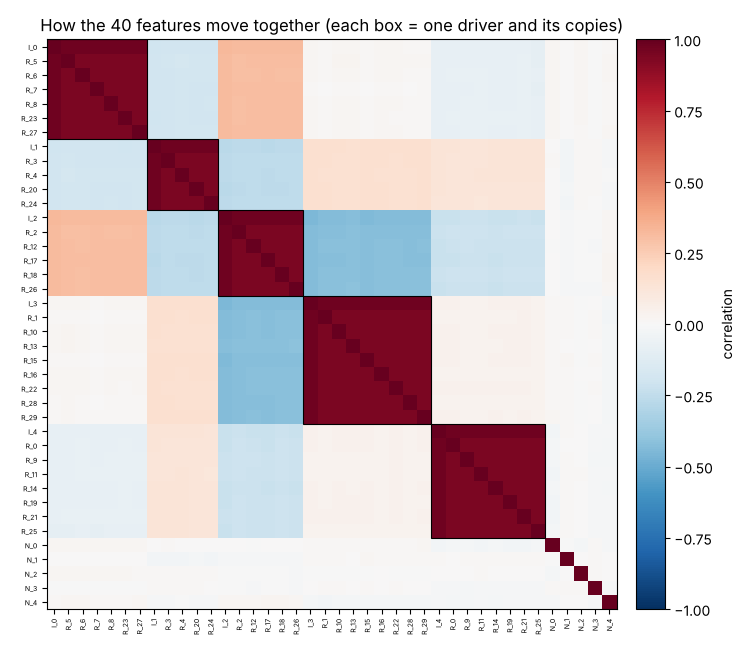

In [ ]:
par = {f"R_{k}": int(j) for k, j in enumerate(parents)}
order = []
for d in range(5):
    order += [f"I_{d}"] + sorted([r for r, q in par.items() if q == d], key=lambda s: int(s[2:]))
order += [c for c in X.columns if c[0] == "N"]
corr_bench = X[order].corr()
copy_corr = pd.Series({r: corr_bench.loc[r, f"I_{q}"] for r, q in par.items()})
drv = [f"I_{d}" for d in range(5)]
drv_max = corr_bench.loc[drv, drv].where(~np.eye(5, dtype=bool)).abs().max().max()
noise_max = corr_bench.loc[[c for c in order if c[0] == "N"], [c for c in order if c[0] != "N"]].abs().max().max()
print(f"copy vs its own driver: correlation {copy_corr.min():.3f} to {copy_corr.max():.3f}")
print(f"drivers with each other: at most {drv_max:.2f} in size; noise with any other feature: at most {noise_max:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr_bench.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=5)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=5)
start = 0
for d in range(5):
    size = 1 + sum(q == d for q in par.values())
    ax.add_patch(plt.Rectangle((start - 0.5, start - 0.5), size, size, fill=False, ec="k", lw=0.8))
    start += size
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label="correlation")
ax.set_title("How the 40 features move together (each box = one driver and its copies)")
plt.tight_layout(); plt.show()

- Each square is one pair of features. Dark red means they move together; white means unrelated. The black boxes mark each driver with its copies.
- Each copy moves with its own driver at a correlation of 0.97, so inside each box the features are near-duplicates. The drivers are only loosely related to each other (at most 0.45 in size), and the noise features relate to nothing (below 0.03).
- The data really holds five pieces of information plus noise, spread across 35 columns. Any score that looks at one column at a time will see the information split up.

## 2 · What do the three usual scores say?

Three standard ways to ask a trained model which features it uses. In the project analogy, each one removes or isolates one person at a time.

- **Split credit: MDI** (mean decrease in impurity). A decision tree splits the data on one feature at a time, and each split makes the groups more uniform. The feature used gets credit for that improvement; adding it up over all trees gives each feature's share, which sums to 100%. Fast, but measured on the same data the model learned from. Setting `max_features=1` makes each split consider one random feature, so a strong feature cannot crowd the others out.
- **Scramble test: MDA** (mean decrease in accuracy). Train the model, then shuffle one feature's column in data the model has not seen and measure how much worse the predictions get: score = log-loss(shuffled) − log-loss(original). Log-loss measures how wrong the predicted probabilities are, so it also catches a feature that makes the model more confident without changing many yes/no calls.
- **Solo test: SFI** (single feature importance). Train a model on one feature alone and score it on unseen data. Nothing can cover for the feature, but the test cannot tell when two features say the same thing.

What to expect if copies matter: split credit and the scramble test spread each driver's credit over its copies; the solo test scores every copy almost as high as its driver.

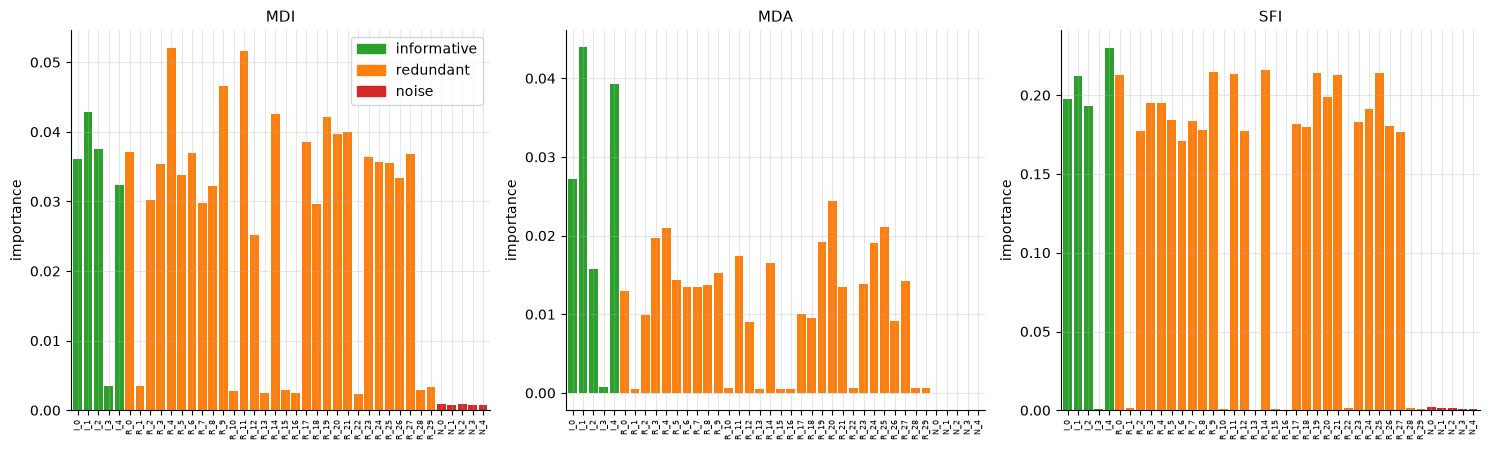

     share on I (5 feat.)  share on R (30 feat.)  share on N (5 feat.)  mean I / mean R  AUC signal vs noise
MDI                 0.152                  0.844                 0.004            1.084                 1.00
MDA                 0.275                  0.725                 0.000            2.276                 1.00
SFI                 0.164                  0.835                 0.001            1.174                 0.84


In [3]:
def rf(seed=0, max_features="sqrt", n=200):
    return RandomForestClassifier(n_estimators=n, max_depth=6, min_samples_leaf=20, max_features=max_features,
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=seed)

def mdi(X, y, seed=0):
    m = rf(seed, max_features=1, n=300).fit(X, y)
    imp = pd.Series(m.feature_importances_, index=X.columns)
    return imp

def mda(X, y, splits, clusters=None, seed=0, n_rep=1):
    """Permutation importance in log-loss terms, averaged over folds. clusters: dict name -> list of columns (permuted jointly)."""
    groups = clusters or {c: [c] for c in X.columns}
    rng = np.random.default_rng(seed)
    out = {g: [] for g in groups}
    for tr, te in splits:
        m = rf(seed).fit(X.iloc[tr], y.iloc[tr])
        Xte, yte = X.iloc[te], y.iloc[te]
        base = log_loss(yte, m.predict_proba(Xte), labels=[0, 1])
        for g, cols in groups.items():
            deltas = []
            for _ in range(n_rep):
                Xp = Xte.copy()
                Xp[cols] = Xte[cols].values[rng.permutation(len(Xte))]
                deltas.append(log_loss(yte, m.predict_proba(Xp), labels=[0, 1]) - base)
            out[g].append(np.mean(deltas))
    out = pd.DataFrame(out)
    return out.mean(), out.mean() / (out.std() / np.sqrt(len(out)))

def sfi(X, y, splits, seed=0):
    res = {}
    for c in X.columns:
        scores = []
        for tr, te in splits:
            m = rf(seed, max_features=1, n=60).fit(X.iloc[tr][[c]], y.iloc[tr])
            scores.append(-log_loss(y.iloc[te], m.predict_proba(X.iloc[te][[c]]), labels=[0, 1]))
        res[c] = np.mean(scores)
    s = pd.Series(res)
    return s - s.min()                      # shift so the worst feature is 0

splits = list(KFold(5, shuffle=True, random_state=0).split(X))
imp_mdi = mdi(X, y)
imp_mda, t_mda = mda(X, y, splits)
imp_sfi = sfi(X, y, splits)
imp = pd.DataFrame({"MDI": imp_mdi, "MDA": imp_mda, "SFI": imp_sfi})
imp_norm = imp.div(imp.sum())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=False)
cmap = {"I": "tab:green", "R": "tab:orange", "N": "tab:red"}
for ax, m in zip(axes, imp):
    imp[m].plot.bar(ax=ax, color=[cmap[kind[c]] for c in imp.index], width=0.85)
    ax.set(title=m, ylabel="importance"); ax.tick_params(axis="x", labelsize=6)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.values()]
axes[0].legend(handles, ["informative", "redundant", "noise"])
plt.tight_layout(); plt.show()

summary = {}
for m in imp:
    s = imp_norm[m]
    summary[m] = {"share on I (5 feat.)": s[kind == "I"].sum(), "share on R (30 feat.)": s[kind == "R"].sum(),
                  "share on N (5 feat.)": s[kind == "N"].sum(),
                  "mean I / mean R": s[kind == "I"].mean() / s[kind == "R"].mean(),
                  "AUC signal vs noise": roc_auc_score((kind != "N").astype(int), imp[m])}
print(pd.DataFrame(summary).T.round(3).to_string())

- One bar per feature, coloured by kind (green driver, orange copy, red noise). A taller bar means the model relies more on that feature.
- All three scores put noise near zero (split credit 0.4% of the total, scramble test 0.0%, solo test 0.1%). They all spread the rest across the 35 driver and copy columns.
- Split credit is nearly flat between drivers and copies (a driver scores only 1.08 times a copy), because every copy gets its share of the in-sample improvement. The scramble test separates them better (2.3 times), because a noisy copy is a worse stand-in on unseen data.
- The solo test does not dilute: each copy scores almost as high as its driver (1.17 times). That is the reverse problem, the same information counted up to nine times. It is also the weakest at telling signal from noise (AUC 0.84 against 1.00), because the weak I_3 family, scored alone, is no better than noise (0.02% per feature against a noise maximum of 0.04%).
- Read one bar at a time, the chart says forty features each matter a little. The truth is five drivers that matter a lot.

### How much credit do copies take away?

The chart above cannot show how much each driver lost, because its undiluted score is unknown there. Removing the copies gives that number: the scramble test is run on the 5 drivers and 5 noise features alone, then again with the 30 copies added. The drivers are identical in both runs; only the copies change.

In [4]:
cols_small = [c for c in X.columns if kind[c] in ("I", "N")]
mda_small, _ = mda(X[cols_small], y, splits)
dil = pd.DataFrame({"MDA, 10 features (no copies)": mda_small[[c for c in cols_small if kind[c] == "I"]],
                    "MDA, 40 features (30 copies added)": imp_mda[[c for c in cols_small if kind[c] == "I"]]})
dil.loc["mean"] = dil.mean()
dil["ratio"] = dil.iloc[:, 1] / dil.iloc[:, 0]
print(dil.round(4).to_string())

      MDA, 10 features (no copies)  MDA, 40 features (30 copies added)   ratio
I_0                         0.1454                              0.0272  0.1869
I_1                         0.2051                              0.0439  0.2142
I_2                         0.0968                              0.0158  0.1632
I_3                         0.0142                              0.0008  0.0552
I_4                         0.2857                              0.0393  0.1376
mean                        0.1495                              0.0254  0.1700


- The first column is each driver's real importance, the second what the test reports once copies exist, the third the share kept.
- The average falls from 0.150 to 0.025: the drivers keep 17% of their importance (between 6% and 21% each). The order survives; the size does not.
- A feature's reported importance depends on how many relatives it has, which nobody controls in a real feature list. Read one bar at a time, the 40-feature chart would call these drivers weak.

### Is it a fluke? 20 fresh datasets

One dataset can flatter or punish a method by chance (which drivers got more copies, how strong each one is). The same summary is repeated on 20 new datasets, each with new random data and a new assignment of copies to drivers (5,000 rows each, 4 folds).

In [5]:
def summarise_run(seed):
    Xs, ys, _ = make_data(seed, n=5000)
    kd = pd.Series([c[0] for c in Xs.columns], index=Xs.columns)
    sp = list(KFold(4, shuffle=True, random_state=seed).split(Xs))
    run = pd.DataFrame({"MDI": mdi(Xs, ys, seed), "MDA": mda(Xs, ys, sp, seed=seed)[0]})
    out = {}
    for m in run:
        s = run[m] / run[m].sum()
        out[m] = {"share on I": s[kd == "I"].sum(), "share on R": s[kd == "R"].sum(), "share on N": s[kd == "N"].sum(),
                  "mean I / mean R": s[kd == "I"].mean() / s[kd == "R"].mean(),
                  "AUC signal vs noise": roc_auc_score((kd != "N").astype(int), run[m])}
    return pd.DataFrame(out).T

reps = pd.concat({s: summarise_run(s) for s in range(20)}, names=["seed", "method"])
rep_tab = reps.groupby("method").agg(["mean", "std"]).round(3)
print(rep_tab.to_string())

       share on I        share on R        share on N        mean I / mean R        AUC signal vs noise     
             mean    std       mean    std       mean    std            mean    std                mean  std
method                                                                                                      
MDA         0.280  0.032      0.720  0.032      0.000  0.000           2.353  0.376                 1.0  0.0
MDI         0.151  0.020      0.843  0.020      0.006  0.002           1.075  0.166                 1.0  0.0


- Each row is a method; the columns give its share of credit on drivers, copies and noise (mean and standard deviation over 20 datasets), the driver-to-copy ratio, and the AUC for telling signal features from noise (1.0 = perfect).
- The scramble test gives the 5 drivers 28.0% ± 3.2% of its total and noise 0.0%; split credit gives the drivers 15.1% ± 2.0% and noise 0.6%. Both rank every signal feature above every noise feature in every dataset (AUC 1.0).
- A driver scores 2.35 times a copy under the scramble test and 1.08 times under split credit, the same as the single run.
- The dilution is systematic, not luck. The scramble test is the better of the two, but it still hands most of the credit to copies.

## 3 · Does testing features as groups fix it?

The copies take credit because the model can fall back on them when one feature is shuffled. The fix takes that option away: group the features that carry the same information and remove each group as a whole. In the analogy, the whole team that knows the task is removed at once.

1. **Group the features** with ONC (optimal number of clusters). It runs k-means on a correlation distance for every possible number of groups and keeps the one where features sit clearly closer to their own group than to any other; weak groups are split again. It uses only the correlations from the first look, never the label.
2. **Group split credit**: add up the split credit of the features in each group.
3. **Group scramble test**: shuffle all features of a group together on unseen data, so no copy is left to fall back on.

What to expect if it works: one group per driver holding exactly its own copies, the noise in a group of its own, and group scores in the same order as the drivers' real importance (0.286, 0.205, 0.145, 0.097, 0.014 from the copy test).

    I  N  R
C0  1  0  6
C1  1  0  4
C2  1  0  5
C3  1  0  8
C4  1  0  7
C5  0  5  0
    clustered MDI  clustered MDA  MDA t-stat composition
C0          0.242          0.206      94.936      I1, R6
C1          0.206          0.241      36.864      I1, R4
C2          0.194          0.095      25.027      I1, R5
C3          0.026          0.007       8.017      I1, R8
C4          0.328          0.452      74.641      I1, R7
C5          0.004          0.000       1.125          N5


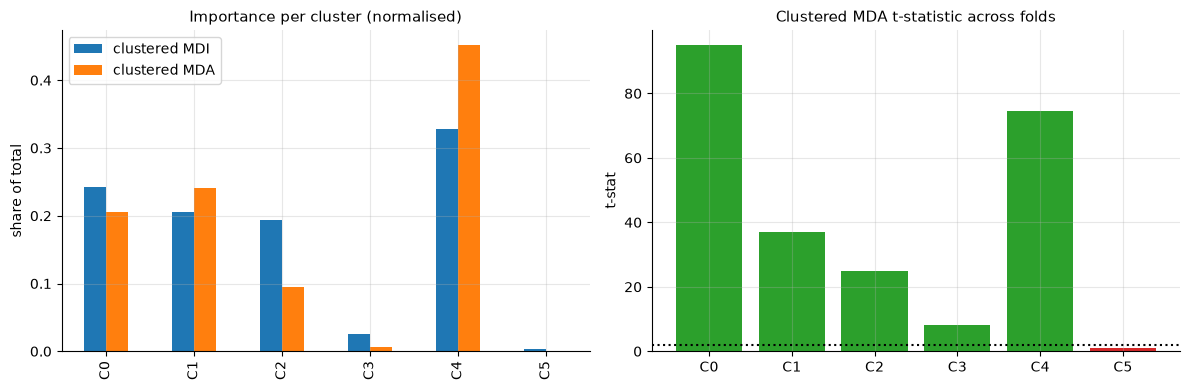

In [6]:
corr_x = X.corr()
labels, _ = qt.onc(corr_x, max_k=20, n_init=5)
clusters = {f"C{c}": list(labels.index[labels == c]) for c in sorted(labels.unique())}
comp = pd.DataFrame({c: pd.Series([kind[f] for f in cols]).value_counts() for c, cols in clusters.items()}).fillna(0).astype(int).T
print(comp.to_string())

cl_mdi = pd.Series({c: imp_mdi[cols].sum() for c, cols in clusters.items()})
cl_mda, cl_t = mda(X, y, splits, clusters=clusters)
cl = pd.DataFrame({"clustered MDI": cl_mdi / cl_mdi.sum(), "clustered MDA": cl_mda / cl_mda.sum(), "MDA t-stat": cl_t})
cl["composition"] = [", ".join(f"{k}{v}" for k, v in comp.loc[c].items() if v) for c in cl.index]
print(cl.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cl[["clustered MDI", "clustered MDA"]].plot.bar(ax=axes[0])
axes[0].set(title="Importance per cluster (normalised)", ylabel="share of total")
axes[1].bar(cl.index, cl_t.values, color=["tab:red" if (comp.loc[c, "I"] == 0 and comp.loc[c, "R"] == 0) else "tab:green" for c in cl.index])
axes[1].axhline(2, color="k", ls=":"); axes[1].set(title="Clustered MDA t-statistic across folds", ylabel="t-stat")
plt.tight_layout(); plt.show()

- The first table counts what each group contains (I = driver, R = copy, N = noise). The second gives each group's share of the group split credit and group scramble score, and a t-statistic: how consistent the scramble score is across the 5 folds (near 0 = no consistent effect).
- ONC finds 6 groups and every one is pure: each holds one driver with exactly its own copies (4 to 8 per group), and the 5 noise features form a group of their own. This was checked copy by copy against the known assignment.
- The group scramble test ranks the groups I_4 (45%), I_1 (24%), I_0 (21%), I_2 (10%), I_3 (1%): the same order as the drivers' real importance (0.286, 0.205, 0.145, 0.097, 0.014). The noise group scores 0.0% with t = 1.1; the weakest real group still has t = 8.0.
- Group split credit also gets noise right (0.4%) but swaps I_0 and I_1 (24% vs 21%), because it rewards groups the trees split on often rather than those that matter on unseen data.
- Forty diluted scores become six scores that match the truth, with no label and no tuning. Use the group scramble test to rank; group split credit is a quick first look.

## 4 · A check that needs no answer key

On real data there is no answer key, so a check is needed that works without one. Rotate the features into principal components: new, uncorrelated combinations of the features, sorted from the one that explains the most shared movement (PC1) to the least. Because they are uncorrelated, no feature can cover for another. A model that learned something real usually relies on the first few components; a model that memorised noise has no reason to prefer them.

The agreement between the credit ranking and the component order is measured with a weighted Kendall τ (1 = same order, 0 = unrelated, top ranks weighted more). It is computed with the real labels and with 10 copies of the data whose labels are shuffled, which shows what agreement looks like by chance.

weighted tau (importance vs eigenvalue rank): real labels 0.59, shuffled labels 0.04 ± 0.16


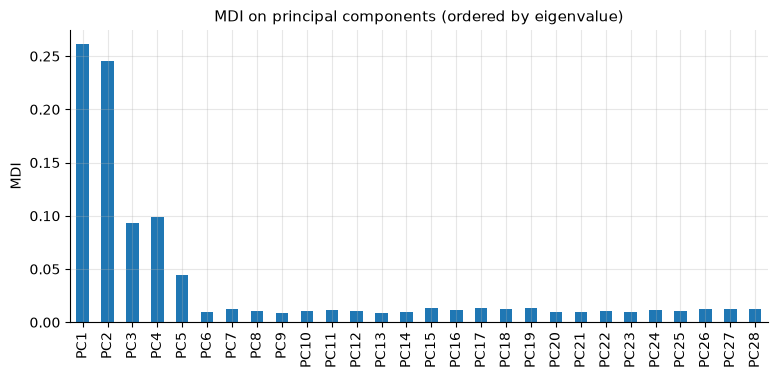

In [7]:
def pca_importance(X, y, seed=0):
    Z = StandardScaler().fit_transform(X)
    pca = PCA().fit(Z)
    P = pd.DataFrame(pca.transform(Z), columns=[f"PC{i+1}" for i in range(Z.shape[1])])
    n_keep = max(int((pca.explained_variance_ratio_.cumsum() <= 0.99).sum()), 5)
    P = P.iloc[:, :n_keep]
    imp = mdi(P, y, seed)
    ev_rank = pd.Series(np.arange(1, P.shape[1] + 1), index=P.columns)
    return imp, weightedtau(imp.values, 1.0 / ev_rank.values).statistic

imp_pc, tau_real = pca_importance(X, y)
taus_null = [pca_importance(X, pd.Series(np.random.default_rng(s).permutation(y.values)), s)[1] for s in range(10)]
print(f"weighted tau (importance vs eigenvalue rank): real labels {tau_real:.2f}, shuffled labels {np.mean(taus_null):.2f} ± {np.std(taus_null):.2f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
imp_pc.plot.bar(ax=ax); ax.set(title="MDI on principal components (ordered by eigenvalue)", ylabel="MDI")
plt.show()

- One bar per component, ordered from most to least shared movement; credit sitting on the left means the model uses the main structure.
- The credit sits on the first five components (PC1 0.26, PC2 0.25, PC3 to PC5 between 0.04 and 0.10), one for each driver; the other 23 hold about 0.01 each.
- Agreement is 0.59 with real labels and 0.04 ± 0.16 with shuffled labels, more than three standard deviations apart.
- If a model's credit does not lean toward the main components, its importance scores probably reflect noise. The check is a warning light, not a proof, because a real signal can sit in a small component.

## 5 · What do price features say about real stocks?

The same procedure on 90 US large-cap stocks. Every 5 trading days, each stock gets one row: its features on that date and what happened over the next 10 days. Every feature uses past prices only.

| Feature | What it measures | Family |
|---|---|---|
| ret_1d, ret_5d, ret_10d, ret_21d, ret_63d, ret_126d, ret_252d | Return over the last 1 day to 1 year, divided by the stock's volatility so calm and jumpy stocks are comparable | Price trend |
| dist_ma50 | How far the price sits above or below its 50-day average, in volatility units | Price trend |
| rsi_14 | Relative strength index: share of recent up-moves versus down-moves over about 14 days, 0 to 100 | Price trend |
| mkt_ret_21d | The average stock's return over the last 21 days | Price trend |
| vol_5d, vol_20d, vol_60d | How jumpy daily returns were over the last 5, 20 and 60 days (standard deviation) | Volatility |
| vol_ratio | Recent volatility divided by longer-run volatility; above 1 means jumpier than usual | Volatility |
| mkt_vol_21d | How jumpy the average stock was over the last 21 days | Volatility |

Within each family the features overlap: returns over 5, 10 and 21 days share most of their days, and the volatility windows measure the same jumpiness over different spans. Four columns of pure random numbers are added as a ruler: they show how big a score is when a feature carries nothing, measured in the same model and folds.

Two things are predicted, each comparing a stock with the other 89 on the same date:
- **Direction**: will the stock beat the median stock over the next 10 days? Large-cap returns are close to unpredictable, so little is expected.
- **Size of the move**: will its move, up or down, be bigger than the median stock's? Jumpy stocks tend to stay jumpy, so this should be predictable. It checks that the method finds a signal when one exists.

Accuracy is reported as AUC: take one stock that ended in the top half and one in the bottom half; AUC is how often the model ranks the first above the second. 0.5 is a coin flip and 1.0 is perfect.

In [8]:
px = du.load_prices("stocks")
lp = np.log(px)
ret = px.pct_change()
vol = ret.ewm(span=20, min_periods=20).std()
H = 10
r1 = lp.diff()
mkt = r1.mean(axis=1)

F = {}
for n in [1, 5, 10, 21, 63, 126, 252]:
    F[f"ret_{n}d"] = lp.diff(n) / (vol * np.sqrt(n))
F["vol_5d"] = r1.rolling(5).std()
F["vol_20d"] = vol
F["vol_60d"] = r1.rolling(60).std()
F["vol_ratio"] = vol / r1.ewm(span=120).std()
F["dist_ma50"] = (px / px.rolling(50).mean() - 1) / vol
gain, loss = r1.clip(lower=0).ewm(alpha=1 / 14).mean(), (-r1.clip(upper=0)).ewm(alpha=1 / 14).mean()
F["rsi_14"] = 100 - 100 / (1 + gain / loss)
F["mkt_ret_21d"] = pd.DataFrame(np.repeat(mkt.rolling(21).sum().values[:, None], px.shape[1], 1), index=px.index, columns=px.columns)
F["mkt_vol_21d"] = pd.DataFrame(np.repeat(mkt.rolling(21).std().values[:, None], px.shape[1], 1), index=px.index, columns=px.columns)

fwd = lp.shift(-H) - lp
dates = px.index[260::5]
dates = dates[dates <= px.index[-H - 1]]
panel = pd.concat({k: v.loc[dates].stack() for k, v in F.items()}, axis=1)
rng = np.random.default_rng(5)
for i in range(4):
    panel[f"noise_{i}"] = rng.normal(size=len(panel))
fwd_s = fwd.loc[dates].stack().reindex(panel.index)
panel["y_dir"] = (fwd_s > fwd_s.groupby(level=0).transform("median")).astype(int)
absf = fwd_s.abs()
panel["y_vol"] = (absf > absf.groupby(level=0).transform("median")).astype(int)
panel = panel.dropna()
panel.index.names = ["date", "stock"]
FEATS = [c for c in panel if not c.startswith("y_")]
print(f"{len(panel):,} stock-dates, {len(FEATS)} features (4 are noise); base rate direction {panel.y_dir.mean():.2f}, volatility {panel.y_vol.mean():.2f}")

48,690 stock-dates, 19 features (4 are noise); base rate direction 0.50, volatility 0.50


### First look at the real features: how much do they overlap?

The rank correlation between every pair of the 15 real features, before any model is trained. Rank (Spearman) correlation is used so a few extreme returns do not dominate.

In [ ]:
raw_feats = [c for c in FEATS if not c.startswith("noise")]
corr_raw = panel[raw_feats].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr_raw.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(raw_feats))); ax.set_xticklabels(raw_feats, rotation=90, fontsize=7)
ax.set_yticks(range(len(raw_feats))); ax.set_yticklabels(raw_feats, fontsize=7)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label="rank correlation")
ax.set_title("How the 15 real price features move together")
plt.tight_layout(); plt.show()
upper = corr_raw.where(np.triu(np.ones(corr_raw.shape, dtype=bool), 1)).stack()
print("Most overlapping pairs (rank correlation):")
print(upper.reindex(upper.abs().sort_values(ascending=False).index).head(8).round(2).to_string())

Pending rerun. Dark red squares are pairs of features that move together and will share credit; the list prints the most overlapping pairs. Expected from the construction: the volatility windows and the overlapping return horizons form the darkest blocks.

### Testing on unseen dates without leaking the future

Each label looks 10 days ahead, and neighbouring dates share most of their future. Random cross-validation would put rows from the same week in training and test, and the model would be scored on outcomes it had partly seen. Instead the dates are cut into 5 blocks in time order; each block is tested in turn, and training rows within 15 days of the test block are dropped (the purge), which is longer than the 10-day label.

In [9]:
def purged_splits(index, n_splits=5, purge_days=15):
    d = index.get_level_values(0)
    ud = np.sort(d.unique())
    blocks = np.array_split(ud, n_splits)
    out = []
    for b in blocks:
        lo, hi = b[0] - np.timedelta64(purge_days, "D"), b[-1] + np.timedelta64(purge_days, "D")
        te = np.where((d >= b[0]) & (d <= b[-1]))[0]
        tr = np.where((d < lo) | (d > hi))[0]
        out.append((tr, te))
    return out

p_splits = purged_splits(panel.index)
print([(len(a), len(b)) for a, b in p_splits])

[(38700, 9810), (38610, 9720), (38610, 9720), (38610, 9720), (38790, 9720)]


### Grouping the real features

The 15 real features are grouped with ONC as in section 3, on their rank correlations. The random columns are left out of the grouping and kept as one-column groups, so they stay a clean ruler.

In [10]:
Xr = panel[FEATS]
real_feats = [c for c in FEATS if not c.startswith("noise")]
corr_r = Xr[real_feats].corr(method="spearman")
lab_r, _ = qt.onc(corr_r, max_k=8, n_init=5, refine_single=True)
clusters_r = {f"K{c}": list(lab_r.index[lab_r == c]) for c in sorted(lab_r.unique())}
clusters_r.update({c: [c] for c in FEATS if c.startswith("noise")})   # noise columns stay alone: they are the control
for k, v in clusters_r.items():
    print(f"{k}: {', '.join(v)}")

K0: ret_1d, ret_5d, ret_10d, ret_21d, ret_63d, ret_126d, ret_252d, dist_ma50, rsi_14, mkt_ret_21d
K1: vol_5d, vol_20d, vol_60d, vol_ratio, mkt_vol_21d
noise_0: noise_0
noise_1: noise_1
noise_2: noise_2
noise_3: noise_3


- ONC finds two groups among the 15 real features. K0 is the **price trend** family: the 7 returns, distance from the 50-day average, RSI and the market's 21-day return. K1 is the **volatility** family: the 3 volatility windows, the volatility ratio and market volatility.
- Short and long return horizons stay in one group; the second pass does not split them. In plain terms the feature set carries two kinds of information: which way the stock has moved, and how much it moves.
- The group tests below compare two blocks of information, plus the four random columns as a ruler.

### Importance for both targets

For each target: the scramble score of every feature, the group scramble score and group split credit of each group, and the out-of-sample AUC. Each group's scramble score is also shown as a multiple of the largest random-column score (the noise ceiling).


=== target y_dir: out-of-sample AUC 0.503 ===
         clustered MDA       t  clustered MDI  × noise ceiling                                                                                        members
K0              0.0002  2.6008         0.5327           2.3833  ret_1d, ret_5d, ret_10d, ret_21d, ret_63d, ret_126d, ret_252d, dist_ma50, rsi_14, mkt_ret_21d
K1              0.0000  0.1065         0.2808           0.3041                                               vol_5d, vol_20d, vol_60d, vol_ratio, mkt_vol_21d
noise_0        -0.0000 -0.7818         0.0516          -0.4400                                                                                        noise_0
noise_1        -0.0000 -3.4133         0.0455          -0.5332                                                                                        noise_1
noise_2        -0.0000 -0.9306         0.0459          -0.3201                                                                                        noise_2
noise

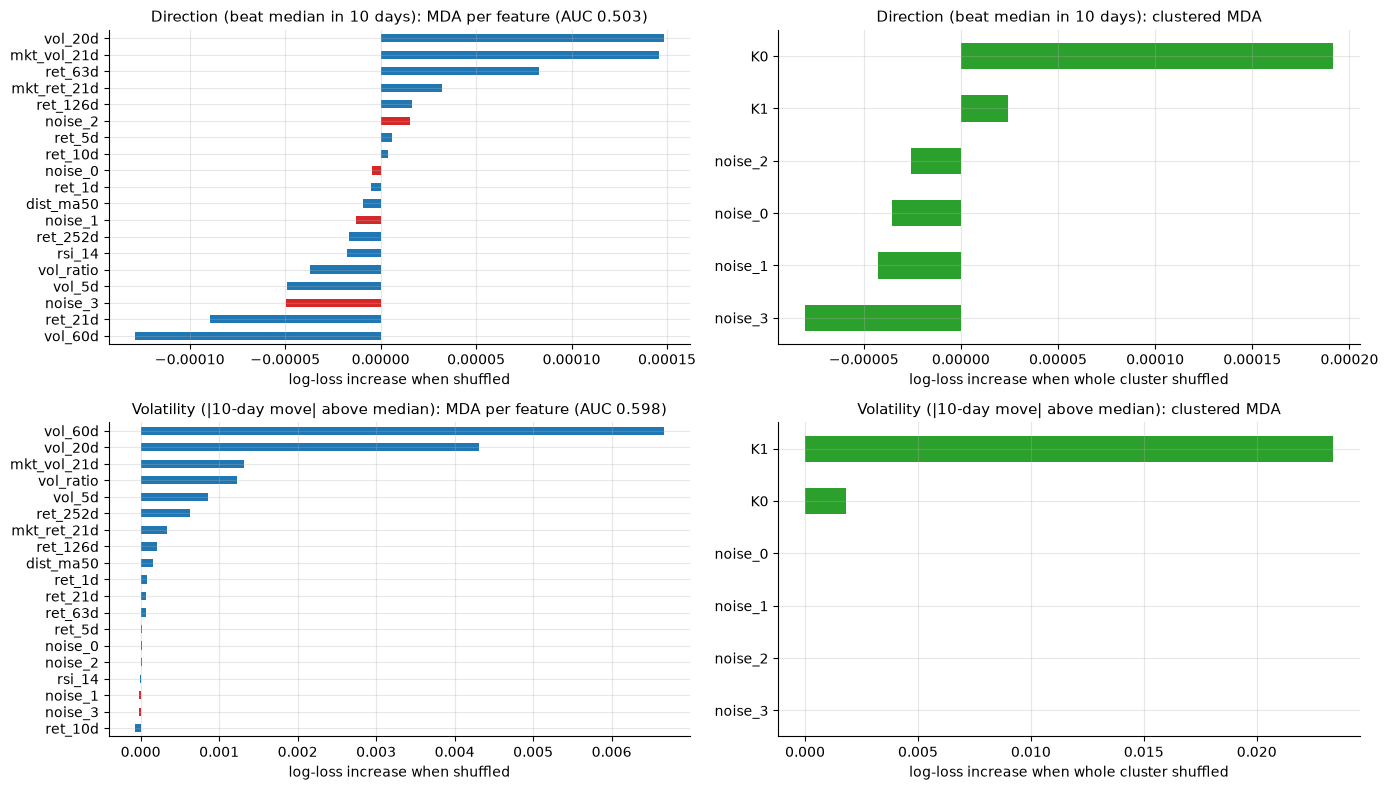

In [11]:
def run_real(target):
    y_t = panel[target]
    m_mda, t_mda = mda(Xr, y_t, p_splits)
    c_mda, c_t = mda(Xr, y_t, p_splits, clusters=clusters_r)
    m_mdi = mdi(Xr, y_t)
    c_mdi = pd.Series({k: m_mdi[v].sum() for k, v in clusters_r.items()})
    aucs = []
    for tr, te in p_splits:
        mdl = rf().fit(Xr.iloc[tr], y_t.iloc[tr])
        aucs.append(roc_auc_score(y_t.iloc[te], mdl.predict_proba(Xr.iloc[te])[:, 1]))
    return pd.DataFrame({"MDA": m_mda, "MDA t": t_mda, "MDI": m_mdi}), pd.DataFrame({"clustered MDA": c_mda, "t": c_t, "clustered MDI": c_mdi}), np.mean(aucs)

real = {t: run_real(t) for t in ["y_dir", "y_vol"]}
for t, (fi, ci, auc) in real.items():
    print(f"\n=== target {t}: out-of-sample AUC {auc:.3f} ===")
    noise_ceiling = ci.loc[[k for k in ci.index if k.startswith("noise")], "clustered MDA"].abs().max()
    ci = ci.assign(**{"× noise ceiling": ci["clustered MDA"] / noise_ceiling})
    print(ci.assign(members=[", ".join(clusters_r[k]) for k in ci.index]).round(4).to_string())
print("\nPer-feature MDA for the volatility target (top 8):")
print(real["y_vol"][0].sort_values("MDA", ascending=False).head(8).round(4).to_string())

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, (t, title) in enumerate([("y_dir", "Direction (beat median in 10 days)"), ("y_vol", "Volatility (|10-day move| above median)")]):
    fi, ci, auc = real[t]
    col = ["tab:red" if c.startswith("noise") else "C0" for c in fi.sort_values("MDA").index]
    fi["MDA"].sort_values().plot.barh(ax=axes[row, 0], color=col)
    axes[row, 0].set(title=f"{title}: MDA per feature (AUC {auc:.3f})", xlabel="log-loss increase when shuffled")
    ci["clustered MDA"].sort_values().plot.barh(ax=axes[row, 1], color="C2")
    axes[row, 1].set(title=f"{title}: clustered MDA", xlabel="log-loss increase when whole cluster shuffled")
plt.tight_layout(); plt.show()

**Direction of the move**
- The AUC says whether the model predicts at all; each group's score says how much worse predictions get when that group is shuffled; the random columns show the size of a score that means nothing.
- AUC 0.503: a coin flip. Past prices do not tell which large-cap stocks will beat the median over the next 10 days.
- The trend group scores 0.0002 (t 2.6) and the volatility group 0.0000. The random columns reach t = −3.4 and −4.0 on the same 5 folds, so a t of 2.6 is within the range of noise. With only 5 folds the t-statistic is unreliable; the AUC and the size of the scores are the evidence.
- Group split credit still hands 81% of its total to the two real groups, because split credit always adds up to 100%. Per feature, a real feature gets 5.4% and a random column 4.7%. Split credit cannot say "there is nothing here".

**Size of the move**
- AUC 0.598: the size of the next 10-day move is clearly predictable from past prices, as expected when jumpy stocks stay jumpy. The method finds a signal when one exists.
- The volatility group scores 0.0234 (t 16.5), 13 times the trend group's 0.0018. One at a time, 60-day and 20-day volatility lead (0.0067 and 0.0043).
- The volatility group's score is 62% larger than its five members' single scores added up (0.0144). Tested one at a time, each volatility measure looks weaker because the others cover for it: the same dilution as in section 2, on real data.
- Group split credit gives the trend group 36% of the credit; the group scramble test gives it 7%. In-sample credit overstates features the trees split on that add little on unseen data.
- Against the noise ceiling, direction scores sit 2.4 times above it and size scores 111 to 1,442 times. A multiple of a few is still noise.
- Price history is useful for forecasting risk (how much a position may swing, how wide a risk limit should be), not for picking which stocks will do better.

## Conclusions

**What holds**
- Testing features one at a time understates any feature with close relatives: copies cut a true driver's scramble score to 17% of its real value (section 2).
- The scramble test on unseen data separates drivers from copies better than split credit (2.35 vs 1.08 times) and never credits noise (section 2).
- Grouping features by correlation and shuffling each group as a whole undoes the dilution: ONC finds all 6 groups exactly, and the group scramble test ranks the drivers in their true order with noise at 0.0% (section 3).
- Credit that follows the main principal components (agreement 0.59 against 0.04 for shuffled labels) is a quick sign that a model learned structure (section 4).
- On 90 US stocks, past prices predict the size of the next 10-day move (AUC 0.598). The volatility group carries it and scores 62% more as a group than its members added up (section 5).

**What does not hold**
- Past prices do not predict 10-day relative direction (AUC 0.503); no group stands clearly above the random columns (section 5).
- Split credit cannot report the absence of a signal: on the direction target it gave 81% of its credit to real features that predict nothing (section 5).
- t-statistics over 5 folds are unreliable: random columns reached |t| = 4.0 (section 5).

**How to prevent it**
1. Draw the correlation heatmap of the features before training. Dark blocks are features that will share credit; here, the five volatility measures form one block.
2. Group features that move together with a clustering method on the correlations, so the groups come from the data.
3. Score groups, not single features: shuffle each whole group on unseen data. Here this turned a "minor" set of volatility features into the model's main signal.
4. Add a few random columns as a ruler; a score within a few times theirs is zero.
5. Check the model beats a coin flip on unseen data (AUC clearly above 0.5) before ranking anything.

Dropping all but one feature per group also removes the dilution, but loses the small extra information each copy may carry; do it after the group test has shown which groups matter.

**Next steps.** Add company fundamentals and cross-sectional features to the direction test; repeat the size target at several horizons; use the group test to trim the feature list before choosing a training label.